ALUNO : Daniel Marques Diniz Maia


MATRÍCULA : 2026061836

TURMA : TM


 1) Explorar os parâmetros epochs (número de iterações),
 função de ativação (ReLU, Tanh, Sigmoid) e n (arquitetura da rede)
 2) Adapte o código Python para ajustar uma função qualquer

 # Definindo a rede

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Domínio de todos os dados.
# Muda a forma: 1-> cria um numero de colunas = 1
# -1 -> deixa PyTorch automaticamente calcular o numero de linhas.
x = torch.linspace(-10, 10, 200).reshape(-1,1)

# Tamanho de cada camada oculta
n = 7


# Função de ativação "Perceptron": degrau (0 se x<=0, 1 se x>0).
# Seu gradiente é nulo em todos os pontos, o que impediria as camadas
# anteriores de aprenderem. Por isso, temos que contornar o problema usando
# o "straight-through estimator": na ida (forward) a saída é o degrau,
# na volta (backward) o gradiente passa como se fosse a identidade.
# Isso adiciona uma camada a mais de complexidade, mas fiz questão de deixar
# aqui para vermos seu efeito para funções matemáticas e compará-lo
# ao XOR (onde funcionou perfeitamente).
class Degrau(nn.Module):
    def forward(self, z):
        saida = (z > 0).float()
        return z + (saida - z).detach()


class DeepPolynomialNN(nn.Module):
    def __init__(self, ativacoes, n=7):
        '''
        ativacoes : lista com 3 CLASSES de ativação,
                    ex.: [nn.Tanh, nn.ReLU, nn.Sigmoid]
        n         : número de neurônios em cada camada oculta
        '''
        super().__init__()

        # Camadas lineares
        self.fc1 = nn.Linear(1, n)   # entrada -> oculta 1
        self.fc2 = nn.Linear(n, n)   # oculta 1 -> oculta 2
        self.fc3 = nn.Linear(n, n)   # oculta 2 -> oculta 3
        self.fc4 = nn.Linear(n, 1)   # oculta 3 -> saída

        # ativacoes[0] é uma classe (p. ex nn.Tanh); o parênteses cria um
        # objeto dessa classe

        self.activation1 = ativacoes[0]()
        self.activation2 = ativacoes[1]()
        self.activation3 = ativacoes[2]()

    def forward(self, x):
        x = self.activation1(self.fc1(x))
        x = self.activation2(self.fc2(x))
        x = self.activation3(self.fc3(x))
        x = self.fc4(x)
        return x



def learning(epochs, funcaodados, ativacoes, titulo=""):
    '''
    Treina a rede de acordo com os argumentos passados, imprime a perda a cada
    250 iterações e plota os resultados. Posteriormente ficará mais clara a
    razão de ter epochs e ativacoes como argumentos

    Parâmetros
    ----------
    epochs : int
        número de iterações.
    funcaodados : function
        função que gera o conjunto de dados (com ruído).
    ativacoes : list
        lista com as 3 classes de ativação da rede.
    titulo : str
        texto extra para o título do gráfico.
    '''
    # Fixando a semente para evitar vieses
    torch.manual_seed(3)

    # Criando os dados com ruído
    y0 = funcaodados(x)
    y = y0 + 0.05 * y0 * (1 - 2 * torch.rand_like(y0))

    # Depois de muitos testes e ajustes ruins, acrescentei essa normalização,
    # o que melhorou significativamente os resultados.  Essa melhora acontece
    # porque a tangente hiperbólica satura a partir de um certo ponto (~5) e
    # sua derivada aproxima-se de zero, dificultando o aprendizado da rede.
    # Normalizar aqui é como passar a medir em metros em vez de decímetros:
    # é como uma mudança de unidades (em que os pesos da rede também são
    # divididos por 10, o que viabiliza essa transformação)
    x_in = x/10


    # Treinando a rede

    model = DeepPolynomialNN(ativacoes, n)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01)

    for e in range(epochs):
        y_pred = model(x_in)
        loss = criterion(y_pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if e % 250 == 0:
            print(f"Epoch {e}, perda: {loss.item():.5f}")

    # Previsão final
    with torch.no_grad():
        y_pred = model(x_in)

    print(f"Perda final: {criterion(y_pred, y).item():.5f}")

    # Plotando os resultados
    plt.figure()
    plt.scatter(x.numpy(), y.numpy(), label="Dados")
    plt.scatter(x.numpy(), y_pred.numpy(), color="red", label="Ajuste NN")
    plt.legend()
    plt.title(f"Ajuste usando rede neural {n}x{n}x{n}\n{titulo}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.show()


# Usando funções do torch em vez do numpy para não termos problemas
funcoesmatematicas = {
    "1": lambda x: torch.sin(3 * x + torch.pi) + torch.sin(x - 2),
    "2": lambda x: (x**3 - 20 * x) / 100,
    "3": lambda x: torch.exp(-x**2 / 10) * torch.cos(2 * x),
}

# Guardamos as CLASSES (sem parênteses); quem instancia é o __init__ da rede.
dicativ = {
    "ReLU": nn.ReLU,
    "Leaky ReLU": nn.LeakyReLU,
    "Perceptron": Degrau,
}

# Para cada uma das 3 funções, treinaremos a rede usando funções de ativação
# diferentes (variando somente a segunda delas) com os epochs fixos, depois
# o contrário (neste caso, a ativação do meio é sempre LeakyReLU)

## Primeiro teste: rede 7x7x7

 Função n° 1
 Ativações variando, epochs fixo = 5000
Funções de ativação: Tanh, ReLU, Sigmoid
Epoch 0, perda: 1.05733
Epoch 250, perda: 0.50481
Epoch 500, perda: 0.42541
Epoch 750, perda: 0.33263
Epoch 1000, perda: 0.24477
Epoch 1250, perda: 0.19635
Epoch 1500, perda: 0.17583
Epoch 1750, perda: 0.16755
Epoch 2000, perda: 0.16209
Epoch 2250, perda: 0.15718
Epoch 2500, perda: 0.12885
Epoch 2750, perda: 0.10676
Epoch 3000, perda: 0.09204
Epoch 3250, perda: 0.08347
Epoch 3500, perda: 0.07200
Epoch 3750, perda: 0.06602
Epoch 4000, perda: 0.06112
Epoch 4250, perda: 0.05917
Epoch 4500, perda: 0.05818
Epoch 4750, perda: 0.05755
Perda final: 0.05711


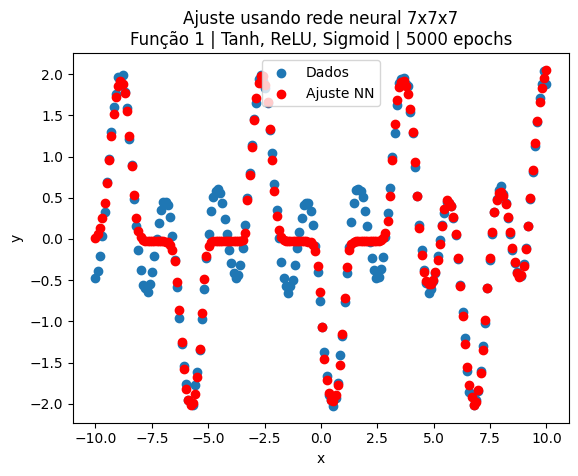

Funções de ativação: Tanh, Leaky ReLU, Sigmoid
Epoch 0, perda: 1.05729
Epoch 250, perda: 0.62229
Epoch 500, perda: 0.39265
Epoch 750, perda: 0.32974
Epoch 1000, perda: 0.28408
Epoch 1250, perda: 0.24922
Epoch 1500, perda: 0.21473
Epoch 1750, perda: 0.19305
Epoch 2000, perda: 0.18272
Epoch 2250, perda: 0.16895
Epoch 2500, perda: 0.11988
Epoch 2750, perda: 0.08774
Epoch 3000, perda: 0.08149
Epoch 3250, perda: 0.07797
Epoch 3500, perda: 0.07652
Epoch 3750, perda: 0.06775
Epoch 4000, perda: 0.06663
Epoch 4250, perda: 0.06282
Epoch 4500, perda: 0.06215
Epoch 4750, perda: 0.06151
Perda final: 0.06093


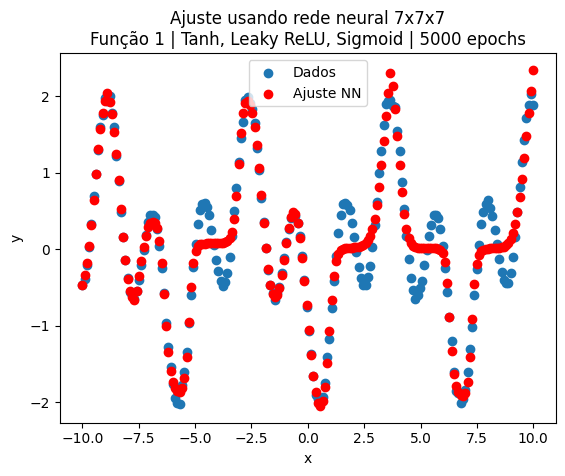

Funções de ativação: Tanh, Perceptron, Sigmoid
Epoch 0, perda: 1.06247
Epoch 250, perda: 1.04323
Epoch 500, perda: 0.96677
Epoch 750, perda: 0.65922
Epoch 1000, perda: 0.64351
Epoch 1250, perda: 0.68417
Epoch 1500, perda: 0.51465
Epoch 1750, perda: 0.52742
Epoch 2000, perda: 0.42194
Epoch 2250, perda: 0.46671
Epoch 2500, perda: 0.47265
Epoch 2750, perda: 0.43830
Epoch 3000, perda: 0.43524
Epoch 3250, perda: 0.44144
Epoch 3500, perda: 0.52746
Epoch 3750, perda: 0.50847
Epoch 4000, perda: 0.49305
Epoch 4250, perda: 0.43659
Epoch 4500, perda: 0.44520
Epoch 4750, perda: 0.46260
Perda final: 0.52711


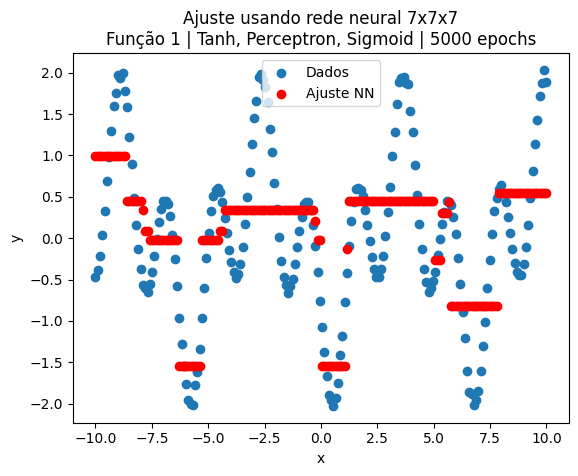

Epochs variando, funções de ativação fixas: Tanh, ReLU, Sigmoid
 N° de epochs: 3000
Epoch 0, perda: 1.05729
Epoch 250, perda: 0.62229
Epoch 500, perda: 0.39265
Epoch 750, perda: 0.32974
Epoch 1000, perda: 0.28408
Epoch 1250, perda: 0.24922
Epoch 1500, perda: 0.21473
Epoch 1750, perda: 0.19305
Epoch 2000, perda: 0.18272
Epoch 2250, perda: 0.16895
Epoch 2500, perda: 0.11988
Epoch 2750, perda: 0.08774
Perda final: 0.08149


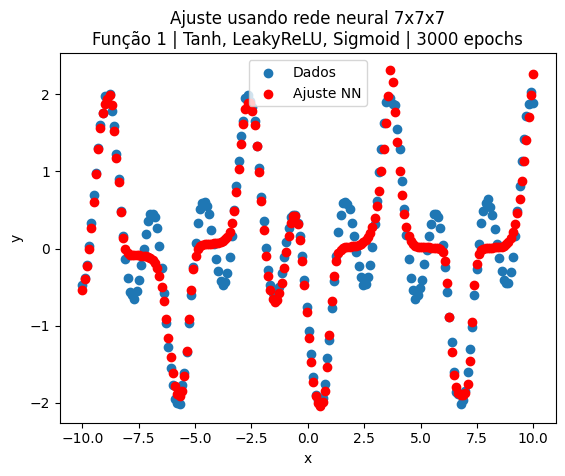

 N° de epochs: 6000
Epoch 0, perda: 1.05729
Epoch 250, perda: 0.62229
Epoch 500, perda: 0.39265
Epoch 750, perda: 0.32974
Epoch 1000, perda: 0.28408
Epoch 1250, perda: 0.24922
Epoch 1500, perda: 0.21473
Epoch 1750, perda: 0.19305
Epoch 2000, perda: 0.18272
Epoch 2250, perda: 0.16895
Epoch 2500, perda: 0.11988
Epoch 2750, perda: 0.08774
Epoch 3000, perda: 0.08149
Epoch 3250, perda: 0.07797
Epoch 3500, perda: 0.07652
Epoch 3750, perda: 0.06775
Epoch 4000, perda: 0.06663
Epoch 4250, perda: 0.06282
Epoch 4500, perda: 0.06215
Epoch 4750, perda: 0.06151
Epoch 5000, perda: 0.06093
Epoch 5250, perda: 0.06038
Epoch 5500, perda: 0.06093
Epoch 5750, perda: 0.05931
Perda final: 0.05882


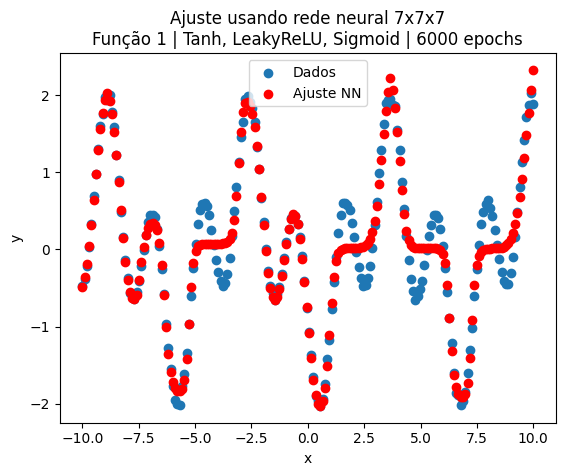

 N° de epochs: 9000
Epoch 0, perda: 1.05729
Epoch 250, perda: 0.62229
Epoch 500, perda: 0.39265
Epoch 750, perda: 0.32974
Epoch 1000, perda: 0.28408
Epoch 1250, perda: 0.24922
Epoch 1500, perda: 0.21473
Epoch 1750, perda: 0.19305
Epoch 2000, perda: 0.18272
Epoch 2250, perda: 0.16895
Epoch 2500, perda: 0.11988
Epoch 2750, perda: 0.08774
Epoch 3000, perda: 0.08149
Epoch 3250, perda: 0.07797
Epoch 3500, perda: 0.07652
Epoch 3750, perda: 0.06775
Epoch 4000, perda: 0.06663
Epoch 4250, perda: 0.06282
Epoch 4500, perda: 0.06215
Epoch 4750, perda: 0.06151
Epoch 5000, perda: 0.06093
Epoch 5250, perda: 0.06038
Epoch 5500, perda: 0.06093
Epoch 5750, perda: 0.05931
Epoch 6000, perda: 0.05882
Epoch 6250, perda: 0.05819
Epoch 6500, perda: 0.05758
Epoch 6750, perda: 0.05720
Epoch 7000, perda: 0.05688
Epoch 7250, perda: 0.05662
Epoch 7500, perda: 0.05732
Epoch 7750, perda: 0.06111
Epoch 8000, perda: 0.05616
Epoch 8250, perda: 0.05634
Epoch 8500, perda: 0.05598
Epoch 8750, perda: 0.05591
Perda final: 0

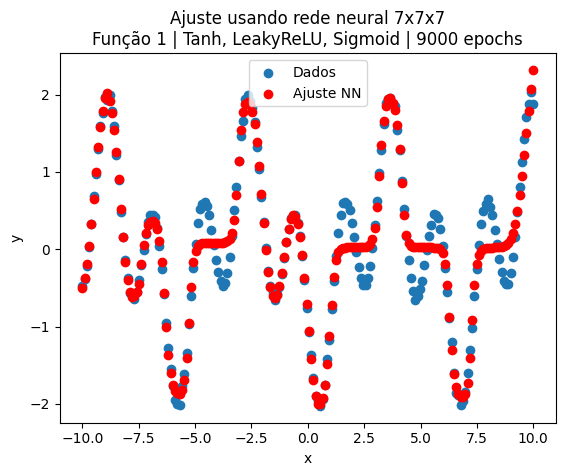

 Função n° 2
 Ativações variando, epochs fixo = 5000
Funções de ativação: Tanh, ReLU, Sigmoid
Epoch 0, perda: 7.91501
Epoch 250, perda: 0.17711
Epoch 500, perda: 0.05185
Epoch 750, perda: 0.03936
Epoch 1000, perda: 0.03693
Epoch 1250, perda: 0.03617
Epoch 1500, perda: 0.03589
Epoch 1750, perda: 0.03542
Epoch 2000, perda: 0.03516
Epoch 2250, perda: 0.03493
Epoch 2500, perda: 0.03472
Epoch 2750, perda: 0.03477
Epoch 3000, perda: 0.03429
Epoch 3250, perda: 0.03563
Epoch 3500, perda: 0.03387
Epoch 3750, perda: 0.03368
Epoch 4000, perda: 0.03352
Epoch 4250, perda: 0.03339
Epoch 4500, perda: 0.03399
Epoch 4750, perda: 0.03328
Perda final: 0.03317


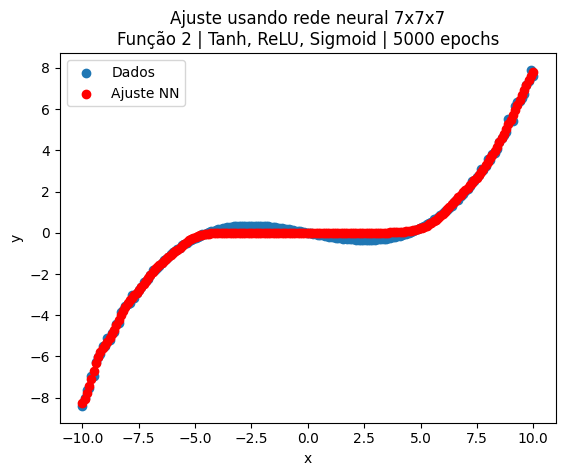

Funções de ativação: Tanh, Leaky ReLU, Sigmoid
Epoch 0, perda: 7.91486
Epoch 250, perda: 0.15604
Epoch 500, perda: 0.02437
Epoch 750, perda: 0.01060
Epoch 1000, perda: 0.00688
Epoch 1250, perda: 0.00573
Epoch 1500, perda: 0.00618
Epoch 1750, perda: 0.00519
Epoch 2000, perda: 0.00662
Epoch 2250, perda: 0.00515
Epoch 2500, perda: 0.00530
Epoch 2750, perda: 0.00501
Epoch 3000, perda: 0.00497
Epoch 3250, perda: 0.00495
Epoch 3500, perda: 0.00493
Epoch 3750, perda: 0.00492
Epoch 4000, perda: 0.00490
Epoch 4250, perda: 0.00489
Epoch 4500, perda: 0.00489
Epoch 4750, perda: 0.00488
Perda final: 0.00489


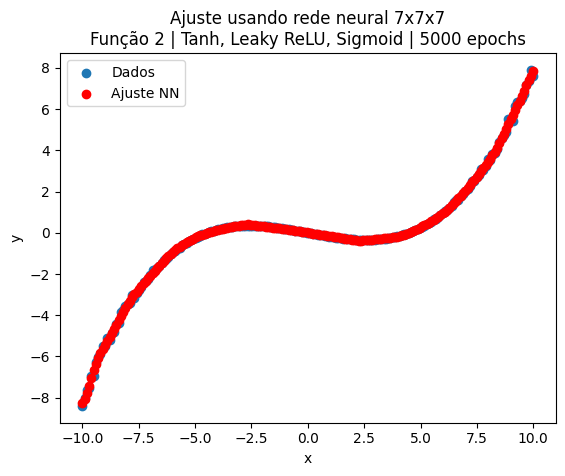

Funções de ativação: Tanh, Perceptron, Sigmoid
Epoch 0, perda: 7.91165
Epoch 250, perda: 4.38602
Epoch 500, perda: 3.15166
Epoch 750, perda: 1.26538
Epoch 1000, perda: 1.00671
Epoch 1250, perda: 0.86678
Epoch 1500, perda: 0.67544
Epoch 1750, perda: 0.52046
Epoch 2000, perda: 0.46250
Epoch 2250, perda: 0.41870
Epoch 2500, perda: 0.41530
Epoch 2750, perda: 0.39758
Epoch 3000, perda: 0.41160
Epoch 3250, perda: 0.41352
Epoch 3500, perda: 0.42878
Epoch 3750, perda: 0.50696
Epoch 4000, perda: 0.54840
Epoch 4250, perda: 0.58996
Epoch 4500, perda: 0.63503
Epoch 4750, perda: 0.69179
Perda final: 0.69455


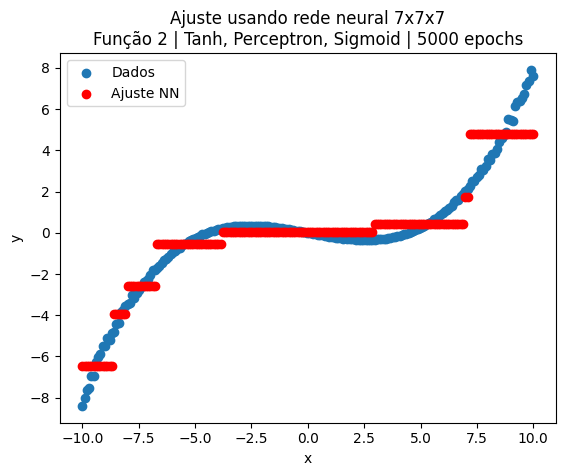

Epochs variando, funções de ativação fixas: Tanh, ReLU, Sigmoid
 N° de epochs: 3000
Epoch 0, perda: 7.91486
Epoch 250, perda: 0.15604
Epoch 500, perda: 0.02437
Epoch 750, perda: 0.01060
Epoch 1000, perda: 0.00688
Epoch 1250, perda: 0.00573
Epoch 1500, perda: 0.00618
Epoch 1750, perda: 0.00519
Epoch 2000, perda: 0.00662
Epoch 2250, perda: 0.00515
Epoch 2500, perda: 0.00530
Epoch 2750, perda: 0.00501
Perda final: 0.00497


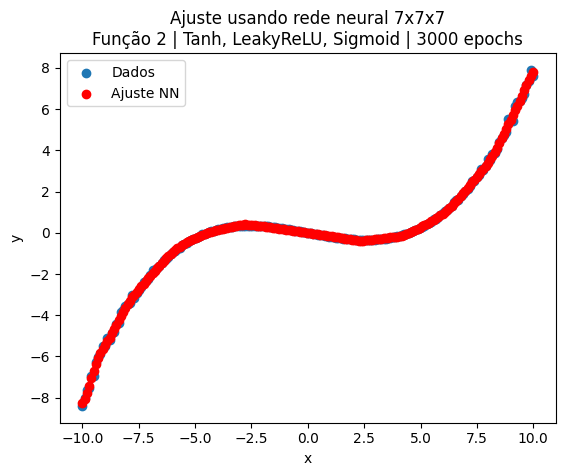

 N° de epochs: 6000
Epoch 0, perda: 7.91486
Epoch 250, perda: 0.15604
Epoch 500, perda: 0.02437
Epoch 750, perda: 0.01060
Epoch 1000, perda: 0.00688
Epoch 1250, perda: 0.00573
Epoch 1500, perda: 0.00618
Epoch 1750, perda: 0.00519
Epoch 2000, perda: 0.00662
Epoch 2250, perda: 0.00515
Epoch 2500, perda: 0.00530
Epoch 2750, perda: 0.00501
Epoch 3000, perda: 0.00497
Epoch 3250, perda: 0.00495
Epoch 3500, perda: 0.00493
Epoch 3750, perda: 0.00492
Epoch 4000, perda: 0.00490
Epoch 4250, perda: 0.00489
Epoch 4500, perda: 0.00489
Epoch 4750, perda: 0.00488
Epoch 5000, perda: 0.00489
Epoch 5250, perda: 0.00486
Epoch 5500, perda: 0.00486
Epoch 5750, perda: 0.00485
Perda final: 0.00486


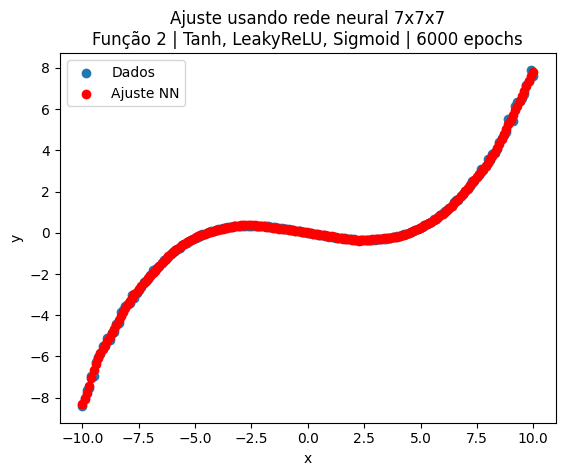

 N° de epochs: 9000
Epoch 0, perda: 7.91486
Epoch 250, perda: 0.15604
Epoch 500, perda: 0.02437
Epoch 750, perda: 0.01060
Epoch 1000, perda: 0.00688
Epoch 1250, perda: 0.00573
Epoch 1500, perda: 0.00618
Epoch 1750, perda: 0.00519
Epoch 2000, perda: 0.00662
Epoch 2250, perda: 0.00515
Epoch 2500, perda: 0.00530
Epoch 2750, perda: 0.00501
Epoch 3000, perda: 0.00497
Epoch 3250, perda: 0.00495
Epoch 3500, perda: 0.00493
Epoch 3750, perda: 0.00492
Epoch 4000, perda: 0.00490
Epoch 4250, perda: 0.00489
Epoch 4500, perda: 0.00489
Epoch 4750, perda: 0.00488
Epoch 5000, perda: 0.00489
Epoch 5250, perda: 0.00486
Epoch 5500, perda: 0.00486
Epoch 5750, perda: 0.00485
Epoch 6000, perda: 0.00486
Epoch 6250, perda: 0.00485
Epoch 6500, perda: 0.00485
Epoch 6750, perda: 0.00512
Epoch 7000, perda: 0.00505
Epoch 7250, perda: 0.00483
Epoch 7500, perda: 0.00859
Epoch 7750, perda: 0.00483
Epoch 8000, perda: 0.00782
Epoch 8250, perda: 0.00515
Epoch 8500, perda: 0.00482
Epoch 8750, perda: 0.00480
Perda final: 0

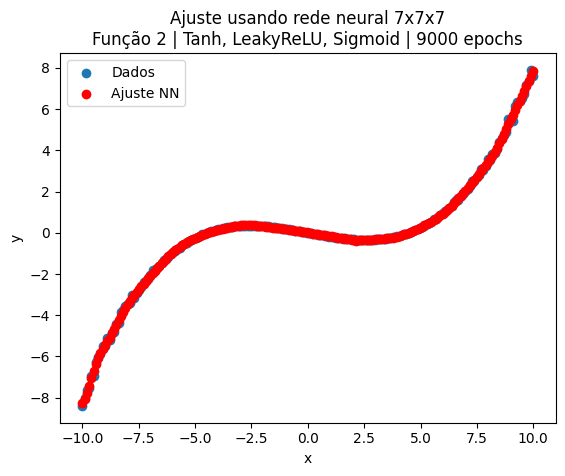

 Função n° 3
 Ativações variando, epochs fixo = 5000
Funções de ativação: Tanh, ReLU, Sigmoid
Epoch 0, perda: 0.11139
Epoch 250, perda: 0.09946
Epoch 500, perda: 0.09946
Epoch 750, perda: 0.09946
Epoch 1000, perda: 0.09946
Epoch 1250, perda: 0.09945
Epoch 1500, perda: 0.09944
Epoch 1750, perda: 0.09942
Epoch 2000, perda: 0.00649
Epoch 2250, perda: 0.00149
Epoch 2500, perda: 0.00086
Epoch 2750, perda: 0.00059
Epoch 3000, perda: 0.00043
Epoch 3250, perda: 0.00028
Epoch 3500, perda: 0.00023
Epoch 3750, perda: 0.00022
Epoch 4000, perda: 0.00021
Epoch 4250, perda: 0.00020
Epoch 4500, perda: 0.00020
Epoch 4750, perda: 0.00019
Perda final: 0.00041


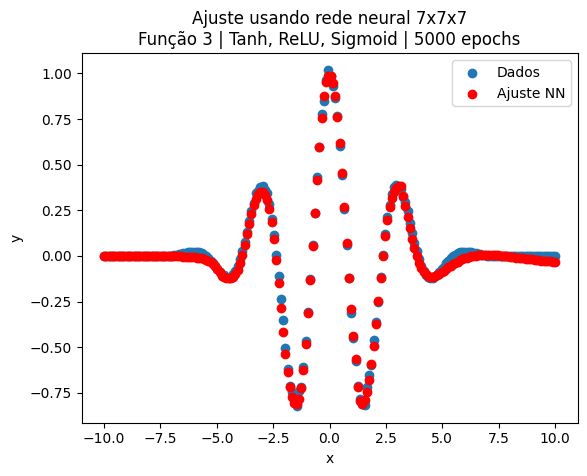

Funções de ativação: Tanh, Leaky ReLU, Sigmoid
Epoch 0, perda: 0.11136
Epoch 250, perda: 0.09946
Epoch 500, perda: 0.09946
Epoch 750, perda: 0.09946
Epoch 1000, perda: 0.09945
Epoch 1250, perda: 0.09944
Epoch 1500, perda: 0.09942
Epoch 1750, perda: 0.09940
Epoch 2000, perda: 0.09879
Epoch 2250, perda: 0.00853
Epoch 2500, perda: 0.00043
Epoch 2750, perda: 0.00022
Epoch 3000, perda: 0.00017
Epoch 3250, perda: 0.00011
Epoch 3500, perda: 0.00015
Epoch 3750, perda: 0.00010
Epoch 4000, perda: 0.00010
Epoch 4250, perda: 0.00009
Epoch 4500, perda: 0.00009
Epoch 4750, perda: 0.00009
Perda final: 0.00009


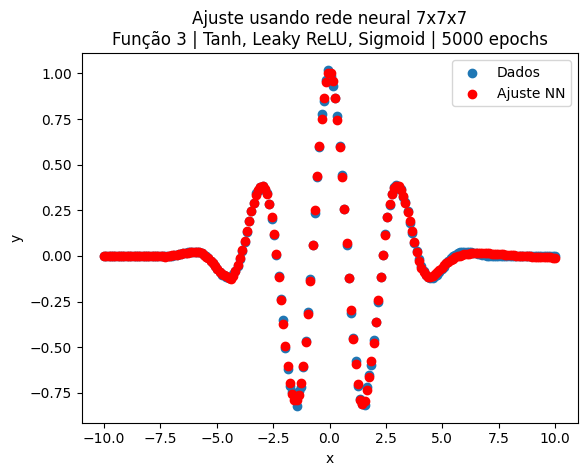

Funções de ativação: Tanh, Perceptron, Sigmoid
Epoch 0, perda: 0.11581
Epoch 250, perda: 0.09956
Epoch 500, perda: 0.09948
Epoch 750, perda: 0.09946
Epoch 1000, perda: 0.09945
Epoch 1250, perda: 0.09951
Epoch 1500, perda: 0.09946
Epoch 1750, perda: 0.09946
Epoch 2000, perda: 0.09946
Epoch 2250, perda: 0.09946
Epoch 2500, perda: 0.09946
Epoch 2750, perda: 0.09946
Epoch 3000, perda: 0.09946
Epoch 3250, perda: 0.09946
Epoch 3500, perda: 0.09946
Epoch 3750, perda: 0.09946
Epoch 4000, perda: 0.09947
Epoch 4250, perda: 0.09951
Epoch 4500, perda: 0.09946
Epoch 4750, perda: 0.09947
Perda final: 0.09947


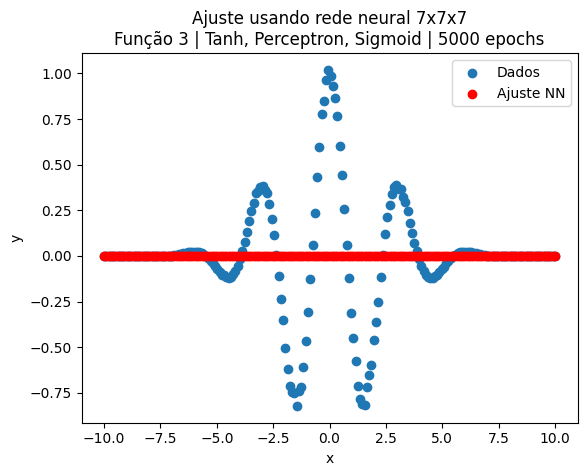

Epochs variando, funções de ativação fixas: Tanh, ReLU, Sigmoid
 N° de epochs: 3000
Epoch 0, perda: 0.11136
Epoch 250, perda: 0.09946
Epoch 500, perda: 0.09946
Epoch 750, perda: 0.09946
Epoch 1000, perda: 0.09945
Epoch 1250, perda: 0.09944
Epoch 1500, perda: 0.09942
Epoch 1750, perda: 0.09940
Epoch 2000, perda: 0.09879
Epoch 2250, perda: 0.00853
Epoch 2500, perda: 0.00043
Epoch 2750, perda: 0.00022
Perda final: 0.00017


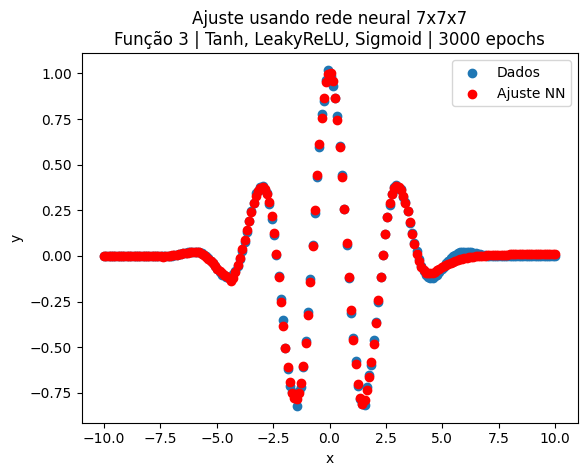

 N° de epochs: 6000
Epoch 0, perda: 0.11136
Epoch 250, perda: 0.09946
Epoch 500, perda: 0.09946
Epoch 750, perda: 0.09946
Epoch 1000, perda: 0.09945
Epoch 1250, perda: 0.09944
Epoch 1500, perda: 0.09942
Epoch 1750, perda: 0.09940
Epoch 2000, perda: 0.09879
Epoch 2250, perda: 0.00853
Epoch 2500, perda: 0.00043
Epoch 2750, perda: 0.00022
Epoch 3000, perda: 0.00017
Epoch 3250, perda: 0.00011
Epoch 3500, perda: 0.00015
Epoch 3750, perda: 0.00010
Epoch 4000, perda: 0.00010
Epoch 4250, perda: 0.00009
Epoch 4500, perda: 0.00009
Epoch 4750, perda: 0.00009
Epoch 5000, perda: 0.00009
Epoch 5250, perda: 0.00009
Epoch 5500, perda: 0.00009
Epoch 5750, perda: 0.00017
Perda final: 0.00008


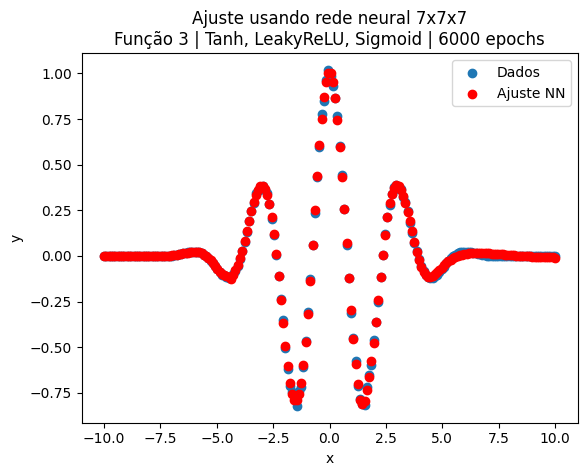

 N° de epochs: 9000
Epoch 0, perda: 0.11136
Epoch 250, perda: 0.09946
Epoch 500, perda: 0.09946
Epoch 750, perda: 0.09946
Epoch 1000, perda: 0.09945
Epoch 1250, perda: 0.09944
Epoch 1500, perda: 0.09942
Epoch 1750, perda: 0.09940
Epoch 2000, perda: 0.09879
Epoch 2250, perda: 0.00853
Epoch 2500, perda: 0.00043
Epoch 2750, perda: 0.00022
Epoch 3000, perda: 0.00017
Epoch 3250, perda: 0.00011
Epoch 3500, perda: 0.00015
Epoch 3750, perda: 0.00010
Epoch 4000, perda: 0.00010
Epoch 4250, perda: 0.00009
Epoch 4500, perda: 0.00009
Epoch 4750, perda: 0.00009
Epoch 5000, perda: 0.00009
Epoch 5250, perda: 0.00009
Epoch 5500, perda: 0.00009
Epoch 5750, perda: 0.00017
Epoch 6000, perda: 0.00008
Epoch 6250, perda: 0.00008
Epoch 6500, perda: 0.00008
Epoch 6750, perda: 0.00008
Epoch 7000, perda: 0.00008
Epoch 7250, perda: 0.00008
Epoch 7500, perda: 0.00007
Epoch 7750, perda: 0.00007
Epoch 8000, perda: 0.00007
Epoch 8250, perda: 0.00007
Epoch 8500, perda: 0.00007
Epoch 8750, perda: 0.00007
Perda final: 0

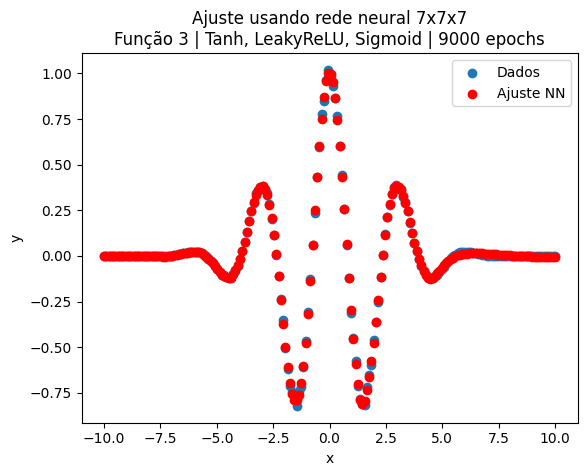

In [3]:
# n já foi definido como 7 na célula anterior
for func in funcoesmatematicas:
    print('=' * 60 + f'\n Função n° {func}\n Ativações variando, epochs fixo = 5000')
    for at in dicativ:
        print('=' * 60 + f'\nFunções de ativação: Tanh, {at}, Sigmoid')
        learning(
            epochs=5000,
            funcaodados=funcoesmatematicas[func],
            ativacoes=[nn.Tanh, dicativ[at], nn.Sigmoid],
            titulo=f"Função {func} | Tanh, {at}, Sigmoid | 5000 epochs",
        )

    print('=' * 60 + '\nEpochs variando, funções de ativação fixas: Tanh, ReLU, Sigmoid')
    for i in [1, 2, 3]:
        print('=' * 60 + f'\n N° de epochs: {i * 3000}')
        learning(
            epochs=i * 3000,
            funcaodados=funcoesmatematicas[func],
            ativacoes=[nn.Tanh, nn.LeakyReLU, nn.Sigmoid],
            titulo=f"Função {func} | Tanh, LeakyReLU, Sigmoid | {i * 3000} epochs",)

Vemos que a perceptron obteve ajustes péssimos para as 3 funções. Seu comportamento binário diminui demais a complexidade da rede, o que pode funcionar para ajustes mais simples (XOR), mas não é o caso aqui.

## Segundo teste: rede 12x12x12

Perceba como aumentar a quantidade de neurônios melhora muito o ajuste da função 1. Isso mostra que o ajuste ruim na rede anterior não se deve à escolha das funções de ativação, mas sim da capacidade da rede.

̄Nota: sem a normalização de x, os ajustes das funções 1 e 3 ficam péssimos. Conforme explicado no código, essa normalização torna a tangente hiperbólica muito mais ativa, melhorando o ajuste.

 Função n° 1
 Ativações variando, epochs fixo = 5000
Funções de ativação: Tanh, ReLU, Sigmoid
Epoch 0, perda: 1.04418
Epoch 250, perda: 0.41381
Epoch 500, perda: 0.35548
Epoch 750, perda: 0.30670
Epoch 1000, perda: 0.22764
Epoch 1250, perda: 0.17318
Epoch 1500, perda: 0.14083
Epoch 1750, perda: 0.13378
Epoch 2000, perda: 0.13785
Epoch 2250, perda: 0.13160
Epoch 2500, perda: 0.13065
Epoch 2750, perda: 0.13679
Epoch 3000, perda: 0.12912
Epoch 3250, perda: 0.12295
Epoch 3500, perda: 0.11139
Epoch 3750, perda: 0.07262
Epoch 4000, perda: 0.01180
Epoch 4250, perda: 0.00529
Epoch 4500, perda: 0.00420
Epoch 4750, perda: 0.00295
Perda final: 0.00333


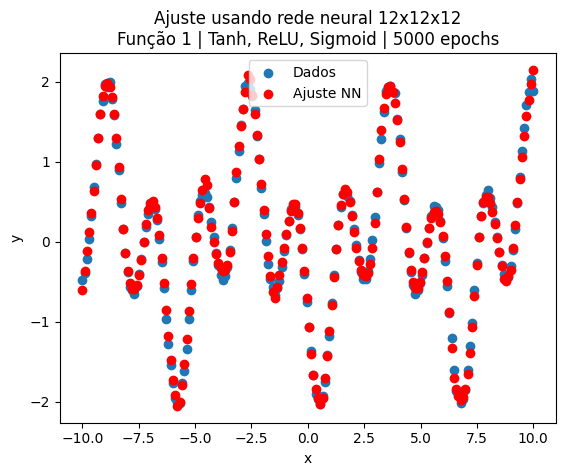

Funções de ativação: Tanh, Leaky ReLU, Sigmoid
Epoch 0, perda: 1.04423
Epoch 250, perda: 0.39372
Epoch 500, perda: 0.31877
Epoch 750, perda: 0.20938
Epoch 1000, perda: 0.10124
Epoch 1250, perda: 0.05306
Epoch 1500, perda: 0.04329
Epoch 1750, perda: 0.03335
Epoch 2000, perda: 0.02917
Epoch 2250, perda: 0.02581
Epoch 2500, perda: 0.01864
Epoch 2750, perda: 0.01146
Epoch 3000, perda: 0.00877
Epoch 3250, perda: 0.00772
Epoch 3500, perda: 0.00682
Epoch 3750, perda: 0.00615
Epoch 4000, perda: 0.00559
Epoch 4250, perda: 0.00947
Epoch 4500, perda: 0.00468
Epoch 4750, perda: 0.00434
Perda final: 0.00692


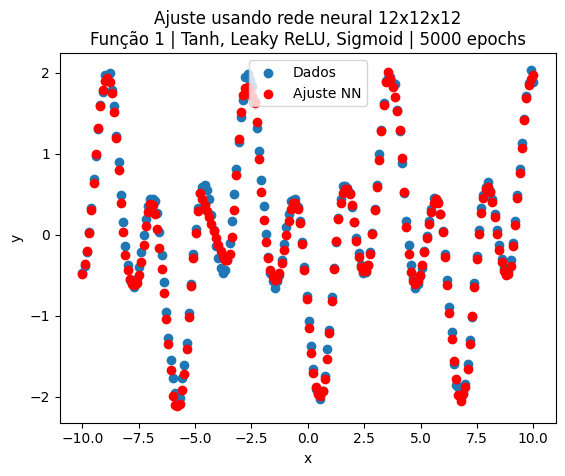

Funções de ativação: Tanh, Perceptron, Sigmoid
Epoch 0, perda: 1.04837
Epoch 250, perda: 1.03244
Epoch 500, perda: 1.03242
Epoch 750, perda: 1.02786
Epoch 1000, perda: 1.03330
Epoch 1250, perda: 0.96935
Epoch 1500, perda: 0.82427
Epoch 1750, perda: 0.84737
Epoch 2000, perda: 0.85105
Epoch 2250, perda: 0.83256
Epoch 2500, perda: 0.84981
Epoch 2750, perda: 0.83707
Epoch 3000, perda: 0.84810
Epoch 3250, perda: 0.86074
Epoch 3500, perda: 0.88066
Epoch 3750, perda: 0.85629
Epoch 4000, perda: 0.89243
Epoch 4250, perda: 0.88615
Epoch 4500, perda: 0.89934
Epoch 4750, perda: 0.89381
Perda final: 0.88478


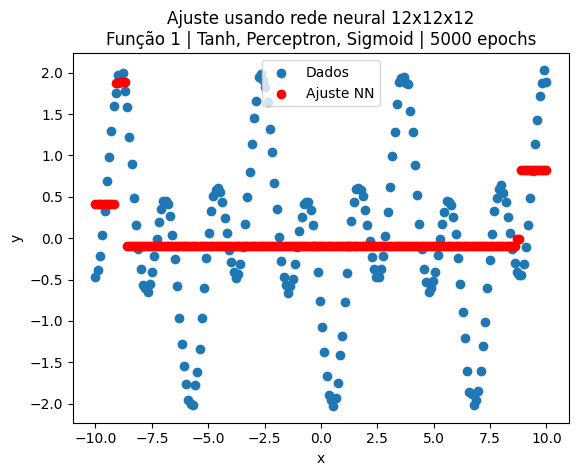

Epochs variando, funções de ativação fixas: Tanh, ReLU, Sigmoid
 N° de epochs: 3000
Epoch 0, perda: 1.04423
Epoch 250, perda: 0.39372
Epoch 500, perda: 0.31877
Epoch 750, perda: 0.20938
Epoch 1000, perda: 0.10124
Epoch 1250, perda: 0.05306
Epoch 1500, perda: 0.04329
Epoch 1750, perda: 0.03335
Epoch 2000, perda: 0.02917
Epoch 2250, perda: 0.02581
Epoch 2500, perda: 0.01864
Epoch 2750, perda: 0.01146
Perda final: 0.00877


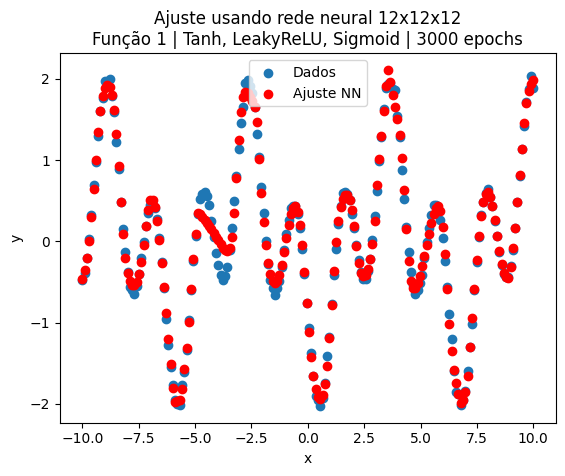

 N° de epochs: 6000
Epoch 0, perda: 1.04423
Epoch 250, perda: 0.39372
Epoch 500, perda: 0.31877
Epoch 750, perda: 0.20938
Epoch 1000, perda: 0.10124
Epoch 1250, perda: 0.05306
Epoch 1500, perda: 0.04329
Epoch 1750, perda: 0.03335
Epoch 2000, perda: 0.02917
Epoch 2250, perda: 0.02581
Epoch 2500, perda: 0.01864
Epoch 2750, perda: 0.01146
Epoch 3000, perda: 0.00877
Epoch 3250, perda: 0.00772
Epoch 3500, perda: 0.00682
Epoch 3750, perda: 0.00615
Epoch 4000, perda: 0.00559
Epoch 4250, perda: 0.00947
Epoch 4500, perda: 0.00468
Epoch 4750, perda: 0.00434
Epoch 5000, perda: 0.00692
Epoch 5250, perda: 0.01158
Epoch 5500, perda: 0.00365
Epoch 5750, perda: 0.00707
Perda final: 0.00438


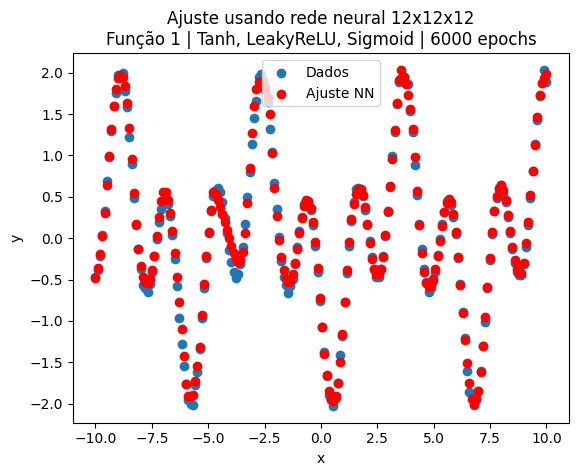

 N° de epochs: 9000
Epoch 0, perda: 1.04423
Epoch 250, perda: 0.39372
Epoch 500, perda: 0.31877
Epoch 750, perda: 0.20938
Epoch 1000, perda: 0.10124
Epoch 1250, perda: 0.05306
Epoch 1500, perda: 0.04329
Epoch 1750, perda: 0.03335
Epoch 2000, perda: 0.02917
Epoch 2250, perda: 0.02581
Epoch 2500, perda: 0.01864
Epoch 2750, perda: 0.01146
Epoch 3000, perda: 0.00877
Epoch 3250, perda: 0.00772
Epoch 3500, perda: 0.00682
Epoch 3750, perda: 0.00615
Epoch 4000, perda: 0.00559
Epoch 4250, perda: 0.00947
Epoch 4500, perda: 0.00468
Epoch 4750, perda: 0.00434
Epoch 5000, perda: 0.00692
Epoch 5250, perda: 0.01158
Epoch 5500, perda: 0.00365
Epoch 5750, perda: 0.00707
Epoch 6000, perda: 0.00438
Epoch 6250, perda: 0.00311
Epoch 6500, perda: 0.00330
Epoch 6750, perda: 0.00299
Epoch 7000, perda: 0.00278
Epoch 7250, perda: 0.00386
Epoch 7500, perda: 0.00286
Epoch 7750, perda: 0.00445
Epoch 8000, perda: 0.00573
Epoch 8250, perda: 0.00292
Epoch 8500, perda: 0.00397
Epoch 8750, perda: 0.00470
Perda final: 0

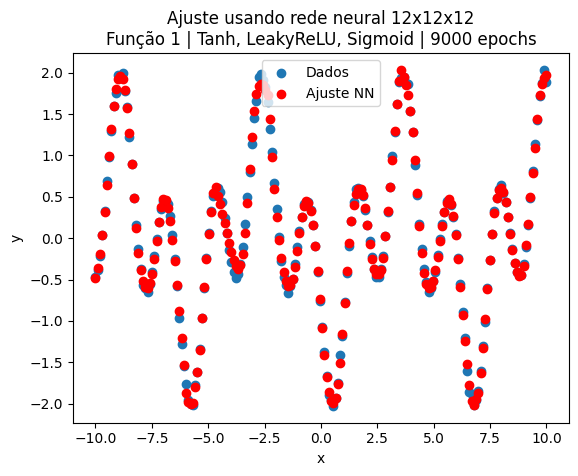

 Função n° 2
 Ativações variando, epochs fixo = 5000
Funções de ativação: Tanh, ReLU, Sigmoid
Epoch 0, perda: 7.98270
Epoch 250, perda: 0.07156
Epoch 500, perda: 0.03979
Epoch 750, perda: 0.03546
Epoch 1000, perda: 0.03388
Epoch 1250, perda: 0.03313
Epoch 1500, perda: 0.03281
Epoch 1750, perda: 0.03270
Epoch 2000, perda: 0.03249
Epoch 2250, perda: 0.03228
Epoch 2500, perda: 0.03238
Epoch 2750, perda: 0.03220
Epoch 3000, perda: 0.03229
Epoch 3250, perda: 0.03217
Epoch 3500, perda: 0.03222
Epoch 3750, perda: 0.03226
Epoch 4000, perda: 0.03231
Epoch 4250, perda: 0.03211
Epoch 4500, perda: 0.03179
Epoch 4750, perda: 0.03189
Perda final: 0.03182


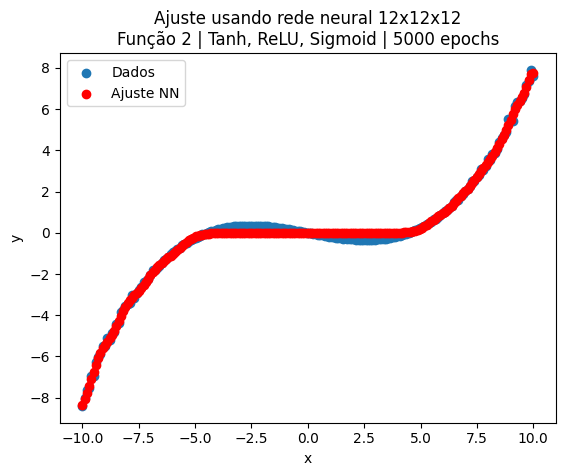

Funções de ativação: Tanh, Leaky ReLU, Sigmoid
Epoch 0, perda: 7.98311
Epoch 250, perda: 0.06380
Epoch 500, perda: 0.01114
Epoch 750, perda: 0.00661
Epoch 1000, perda: 0.00531
Epoch 1250, perda: 0.00495
Epoch 1500, perda: 0.00483
Epoch 1750, perda: 0.00478
Epoch 2000, perda: 0.00463
Epoch 2250, perda: 0.00580
Epoch 2500, perda: 0.00445
Epoch 2750, perda: 0.00465
Epoch 3000, perda: 0.00472
Epoch 3250, perda: 0.00448
Epoch 3500, perda: 0.00449
Epoch 3750, perda: 0.00429
Epoch 4000, perda: 0.00421
Epoch 4250, perda: 0.00444
Epoch 4500, perda: 0.00430
Epoch 4750, perda: 0.00417
Perda final: 0.00441


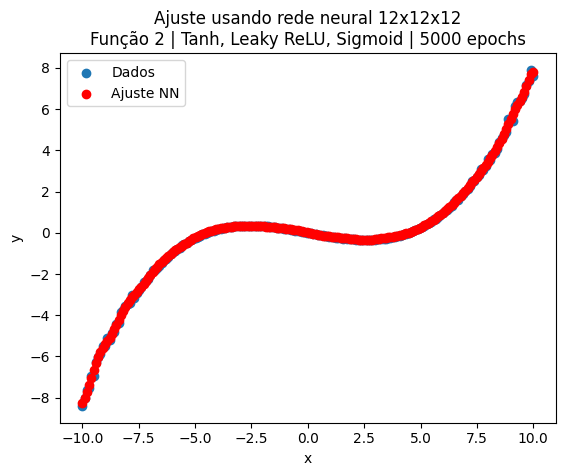

Funções de ativação: Tanh, Perceptron, Sigmoid
Epoch 0, perda: 7.93998
Epoch 250, perda: 4.11423
Epoch 500, perda: 3.71084
Epoch 750, perda: 1.61621
Epoch 1000, perda: 1.13649
Epoch 1250, perda: 0.73258
Epoch 1500, perda: 0.52794
Epoch 1750, perda: 0.49853
Epoch 2000, perda: 0.47955
Epoch 2250, perda: 0.35965
Epoch 2500, perda: 0.30929
Epoch 2750, perda: 0.31909
Epoch 3000, perda: 0.33793
Epoch 3250, perda: 0.37250
Epoch 3500, perda: 0.38260
Epoch 3750, perda: 0.43089
Epoch 4000, perda: 0.43834
Epoch 4250, perda: 0.44993
Epoch 4500, perda: 0.45042
Epoch 4750, perda: 0.44182
Perda final: 0.44623


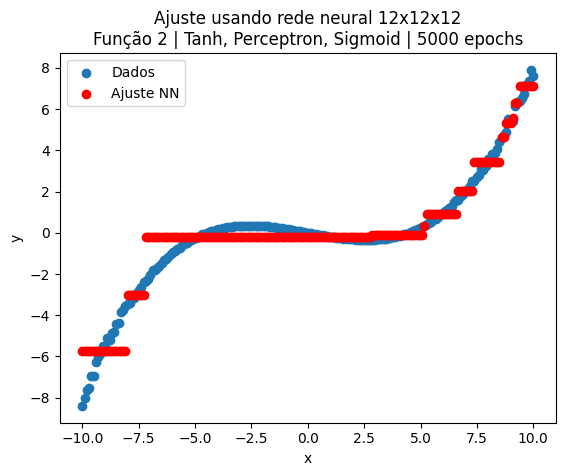

Epochs variando, funções de ativação fixas: Tanh, ReLU, Sigmoid
 N° de epochs: 3000
Epoch 0, perda: 7.98311
Epoch 250, perda: 0.06380
Epoch 500, perda: 0.01114
Epoch 750, perda: 0.00661
Epoch 1000, perda: 0.00531
Epoch 1250, perda: 0.00495
Epoch 1500, perda: 0.00483
Epoch 1750, perda: 0.00478
Epoch 2000, perda: 0.00463
Epoch 2250, perda: 0.00580
Epoch 2500, perda: 0.00445
Epoch 2750, perda: 0.00465
Perda final: 0.00472


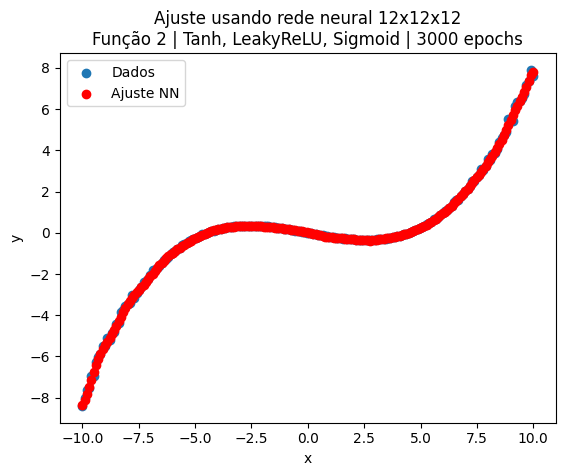

 N° de epochs: 6000
Epoch 0, perda: 7.98311
Epoch 250, perda: 0.06380
Epoch 500, perda: 0.01114
Epoch 750, perda: 0.00661
Epoch 1000, perda: 0.00531
Epoch 1250, perda: 0.00495
Epoch 1500, perda: 0.00483
Epoch 1750, perda: 0.00478
Epoch 2000, perda: 0.00463
Epoch 2250, perda: 0.00580
Epoch 2500, perda: 0.00445
Epoch 2750, perda: 0.00465
Epoch 3000, perda: 0.00472
Epoch 3250, perda: 0.00448
Epoch 3500, perda: 0.00449
Epoch 3750, perda: 0.00429
Epoch 4000, perda: 0.00421
Epoch 4250, perda: 0.00444
Epoch 4500, perda: 0.00430
Epoch 4750, perda: 0.00417
Epoch 5000, perda: 0.00441
Epoch 5250, perda: 0.00424
Epoch 5500, perda: 0.00409
Epoch 5750, perda: 0.00404
Perda final: 0.00430


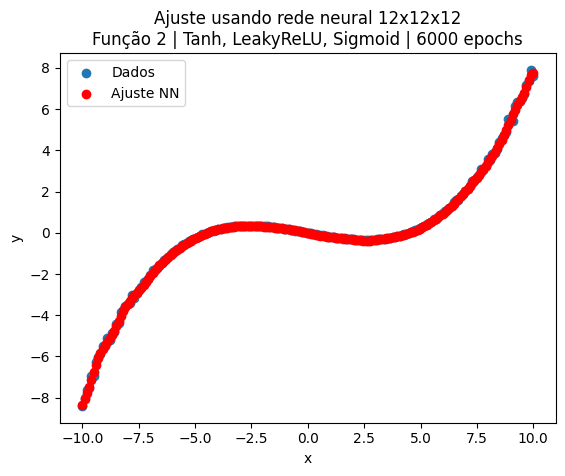

 N° de epochs: 9000
Epoch 0, perda: 7.98311
Epoch 250, perda: 0.06380
Epoch 500, perda: 0.01114
Epoch 750, perda: 0.00661
Epoch 1000, perda: 0.00531
Epoch 1250, perda: 0.00495
Epoch 1500, perda: 0.00483
Epoch 1750, perda: 0.00478
Epoch 2000, perda: 0.00463
Epoch 2250, perda: 0.00580
Epoch 2500, perda: 0.00445
Epoch 2750, perda: 0.00465
Epoch 3000, perda: 0.00472
Epoch 3250, perda: 0.00448
Epoch 3500, perda: 0.00449
Epoch 3750, perda: 0.00429
Epoch 4000, perda: 0.00421
Epoch 4250, perda: 0.00444
Epoch 4500, perda: 0.00430
Epoch 4750, perda: 0.00417
Epoch 5000, perda: 0.00441
Epoch 5250, perda: 0.00424
Epoch 5500, perda: 0.00409
Epoch 5750, perda: 0.00404
Epoch 6000, perda: 0.00430
Epoch 6250, perda: 0.00416
Epoch 6500, perda: 0.00413
Epoch 6750, perda: 0.00404
Epoch 7000, perda: 0.00427
Epoch 7250, perda: 0.00424
Epoch 7500, perda: 0.00400
Epoch 7750, perda: 0.00379
Epoch 8000, perda: 0.00427
Epoch 8250, perda: 0.00398
Epoch 8500, perda: 0.00384
Epoch 8750, perda: 0.00379
Perda final: 0

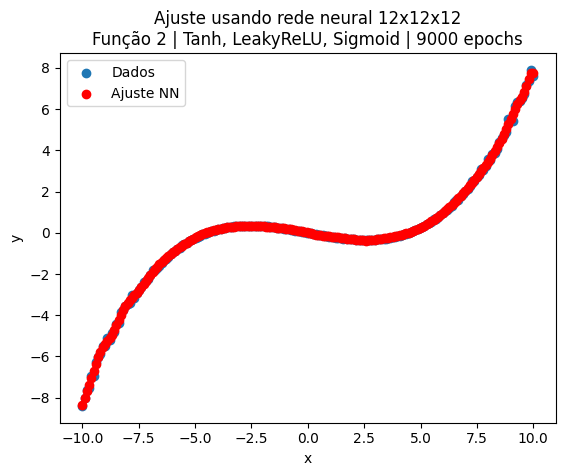

 Função n° 3
 Ativações variando, epochs fixo = 5000
Funções de ativação: Tanh, ReLU, Sigmoid
Epoch 0, perda: 0.12455
Epoch 250, perda: 0.00695
Epoch 500, perda: 0.00058
Epoch 750, perda: 0.00032
Epoch 1000, perda: 0.00027
Epoch 1250, perda: 0.00026
Epoch 1500, perda: 0.00031
Epoch 1750, perda: 0.00022
Epoch 2000, perda: 0.00021
Epoch 2250, perda: 0.00019
Epoch 2500, perda: 0.00018
Epoch 2750, perda: 0.00017
Epoch 3000, perda: 0.00016
Epoch 3250, perda: 0.00015
Epoch 3500, perda: 0.00014
Epoch 3750, perda: 0.00014
Epoch 4000, perda: 0.00013
Epoch 4250, perda: 0.00012
Epoch 4500, perda: 0.00051
Epoch 4750, perda: 0.00011
Perda final: 0.00011


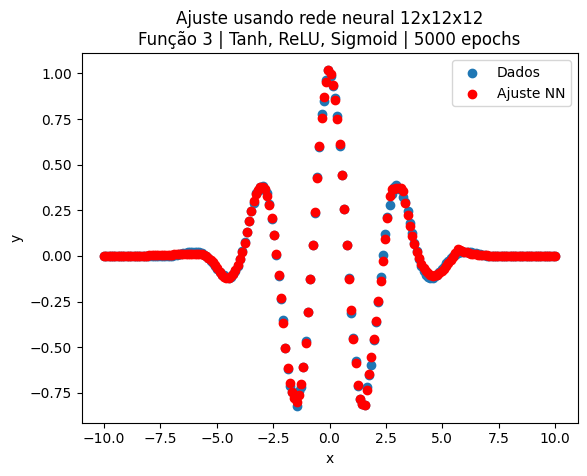

Funções de ativação: Tanh, Leaky ReLU, Sigmoid
Epoch 0, perda: 0.12462
Epoch 250, perda: 0.00555
Epoch 500, perda: 0.00049
Epoch 750, perda: 0.00039
Epoch 1000, perda: 0.00029
Epoch 1250, perda: 0.00025
Epoch 1500, perda: 0.00023
Epoch 1750, perda: 0.00019
Epoch 2000, perda: 0.00017
Epoch 2250, perda: 0.00015
Epoch 2500, perda: 0.00014
Epoch 2750, perda: 0.00014
Epoch 3000, perda: 0.00012
Epoch 3250, perda: 0.00011
Epoch 3500, perda: 0.00011
Epoch 3750, perda: 0.00053
Epoch 4000, perda: 0.00009
Epoch 4250, perda: 0.00009
Epoch 4500, perda: 0.00008
Epoch 4750, perda: 0.00009
Perda final: 0.00009


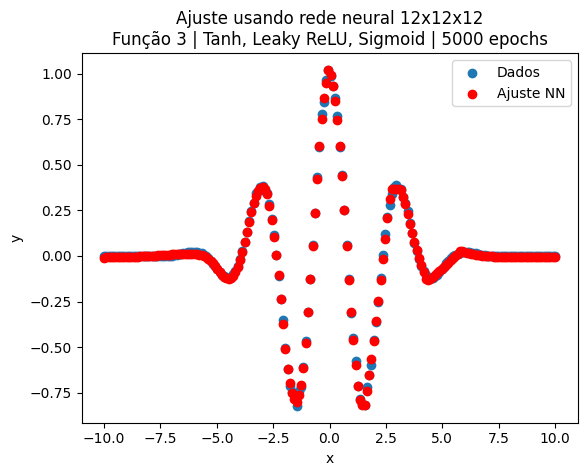

Funções de ativação: Tanh, Perceptron, Sigmoid
Epoch 0, perda: 0.12772
Epoch 250, perda: 0.09834
Epoch 500, perda: 0.09938
Epoch 750, perda: 0.09909
Epoch 1000, perda: 0.09950
Epoch 1250, perda: 0.09946
Epoch 1500, perda: 0.09946
Epoch 1750, perda: 0.09945
Epoch 2000, perda: 0.09946
Epoch 2250, perda: 0.09946
Epoch 2500, perda: 0.09946
Epoch 2750, perda: 0.09946
Epoch 3000, perda: 0.09946
Epoch 3250, perda: 0.09946
Epoch 3500, perda: 0.09950
Epoch 3750, perda: 0.09946
Epoch 4000, perda: 0.09946
Epoch 4250, perda: 0.09946
Epoch 4500, perda: 0.09946
Epoch 4750, perda: 0.09946
Perda final: 0.09946


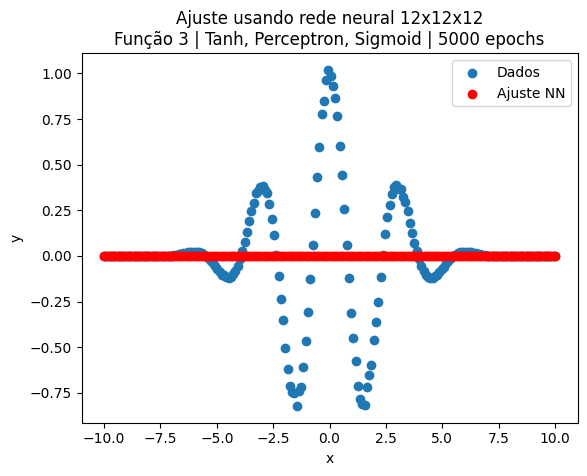

Epochs variando, funções de ativação fixas: Tanh, ReLU, Sigmoid
 N° de epochs: 3000
Epoch 0, perda: 0.12462
Epoch 250, perda: 0.00555
Epoch 500, perda: 0.00049
Epoch 750, perda: 0.00039
Epoch 1000, perda: 0.00029
Epoch 1250, perda: 0.00025
Epoch 1500, perda: 0.00023
Epoch 1750, perda: 0.00019
Epoch 2000, perda: 0.00017
Epoch 2250, perda: 0.00015
Epoch 2500, perda: 0.00014
Epoch 2750, perda: 0.00014
Perda final: 0.00012


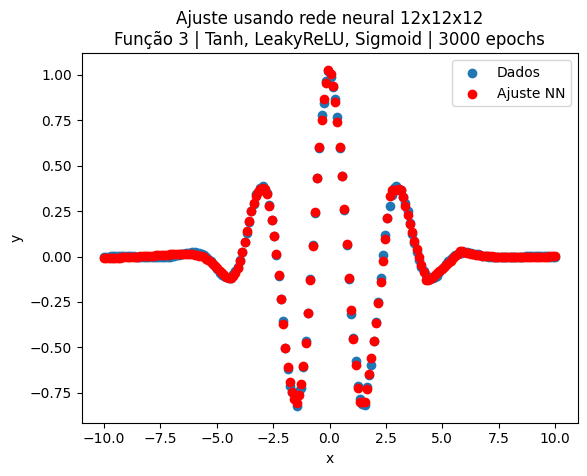

 N° de epochs: 6000
Epoch 0, perda: 0.12462
Epoch 250, perda: 0.00555
Epoch 500, perda: 0.00049
Epoch 750, perda: 0.00039
Epoch 1000, perda: 0.00029
Epoch 1250, perda: 0.00025
Epoch 1500, perda: 0.00023
Epoch 1750, perda: 0.00019
Epoch 2000, perda: 0.00017
Epoch 2250, perda: 0.00015
Epoch 2500, perda: 0.00014
Epoch 2750, perda: 0.00014
Epoch 3000, perda: 0.00012
Epoch 3250, perda: 0.00011
Epoch 3500, perda: 0.00011
Epoch 3750, perda: 0.00053
Epoch 4000, perda: 0.00009
Epoch 4250, perda: 0.00009
Epoch 4500, perda: 0.00008
Epoch 4750, perda: 0.00009
Epoch 5000, perda: 0.00009
Epoch 5250, perda: 0.00011
Epoch 5500, perda: 0.00007
Epoch 5750, perda: 0.00008
Perda final: 0.00007


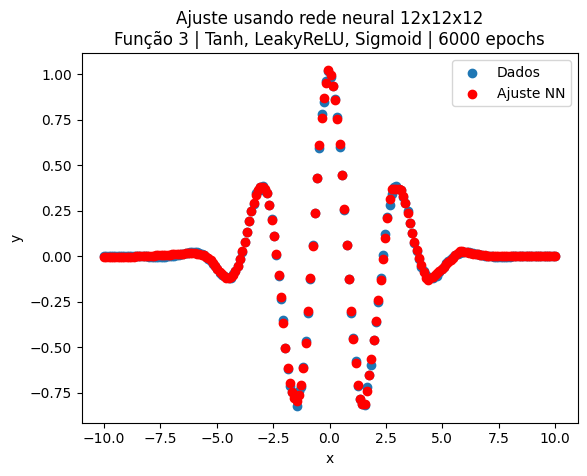

 N° de epochs: 9000
Epoch 0, perda: 0.12462
Epoch 250, perda: 0.00555
Epoch 500, perda: 0.00049
Epoch 750, perda: 0.00039
Epoch 1000, perda: 0.00029
Epoch 1250, perda: 0.00025
Epoch 1500, perda: 0.00023
Epoch 1750, perda: 0.00019
Epoch 2000, perda: 0.00017
Epoch 2250, perda: 0.00015
Epoch 2500, perda: 0.00014
Epoch 2750, perda: 0.00014
Epoch 3000, perda: 0.00012
Epoch 3250, perda: 0.00011
Epoch 3500, perda: 0.00011
Epoch 3750, perda: 0.00053
Epoch 4000, perda: 0.00009
Epoch 4250, perda: 0.00009
Epoch 4500, perda: 0.00008
Epoch 4750, perda: 0.00009
Epoch 5000, perda: 0.00009
Epoch 5250, perda: 0.00011
Epoch 5500, perda: 0.00007
Epoch 5750, perda: 0.00008
Epoch 6000, perda: 0.00007
Epoch 6250, perda: 0.00007
Epoch 6500, perda: 0.00007
Epoch 6750, perda: 0.00011
Epoch 7000, perda: 0.00007
Epoch 7250, perda: 0.00037
Epoch 7500, perda: 0.00007
Epoch 7750, perda: 0.00009
Epoch 8000, perda: 0.00008
Epoch 8250, perda: 0.00006
Epoch 8500, perda: 0.00006
Epoch 8750, perda: 0.00006
Perda final: 0

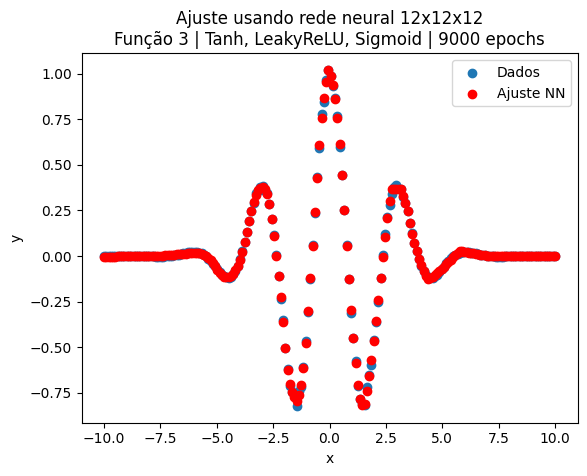

In [4]:
n = 12

for func in funcoesmatematicas:
    print('=' * 60 + f'\n Função n° {func}\n Ativações variando, epochs fixo = 5000')
    for at in dicativ:
        print('=' * 60 + f'\nFunções de ativação: Tanh, {at}, Sigmoid')
        learning(
            epochs=5000,
            funcaodados=funcoesmatematicas[func],
            ativacoes=[nn.Tanh, dicativ[at], nn.Sigmoid],
            titulo=f"Função {func} | Tanh, {at}, Sigmoid | 5000 epochs",
        )

    print('=' * 60 + '\nEpochs variando, funções de ativação fixas: Tanh, ReLU, Sigmoid')
    for i in [1, 2, 3]:
        print('=' * 60 + f'\n N° de epochs: {i * 3000}')
        learning(
            epochs=i * 3000,
            funcaodados=funcoesmatematicas[func],
            ativacoes=[nn.Tanh, nn.LeakyReLU, nn.Sigmoid],
            titulo=f"Função {func} | Tanh, LeakyReLU, Sigmoid | {i * 3000} epochs",
        )